# 01 Look at the data + hand-label lots

Check that images and labels line up, then make the ground truth for the fit rule.

**Inputs**
- `data/raw/6950/naip/<GEOID>.tif`
- `data/raw/6950/labels/<GEOID>.tif`
- `data/raw/6950/parcels/*.gpkg`

**Output**
- `docs/figures/01_image_vs_label.png`, `docs/figures/01_class_shares.png`
- `data/processed/hand_labels.csv  (lot_id, county, fits, fits_keep_trees)` (optional, filled in by hand)

Run `python musa6950/get_data.py` first. Use the geoai env.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
boxes = gpd.read_file(R6 / "sample_boxes.gpkg")
have = boxes.GEOID.map(lambda g: (R6 / "naip" / f"{g}.tif").exists() and (R6 / "labels" / f"{g}.tif").exists())
print(f"{len(boxes)} boxes picked, {have.sum()} have image + label. Missing (no 2022 NAIP in PA):", list(boxes.GEOID[~have]))
boxes = boxes[have].reset_index(drop=True)
boxes.groupby(["split", "stratum"]).size()

177 boxes picked, 173 have image + label. Missing (no 2022 NAIP in PA): ['42115032100', '42083420500', '42083420300', '42083420100']


split  stratum 
test   rural        7
       suburban    10
       urban       10
train  rural       47
       suburban    49
       urban       50
dtype: int64

## Image next to label

- Bands 1-3 = RGB, band 4 = NIR
- Labels: 0 other, 1 building, 2 tree, 3 open, 255 no data
- Labels were already put on the NAIP grid by `get_data.py` (nearest, 1 m to 0.6 m)

same grid: True True


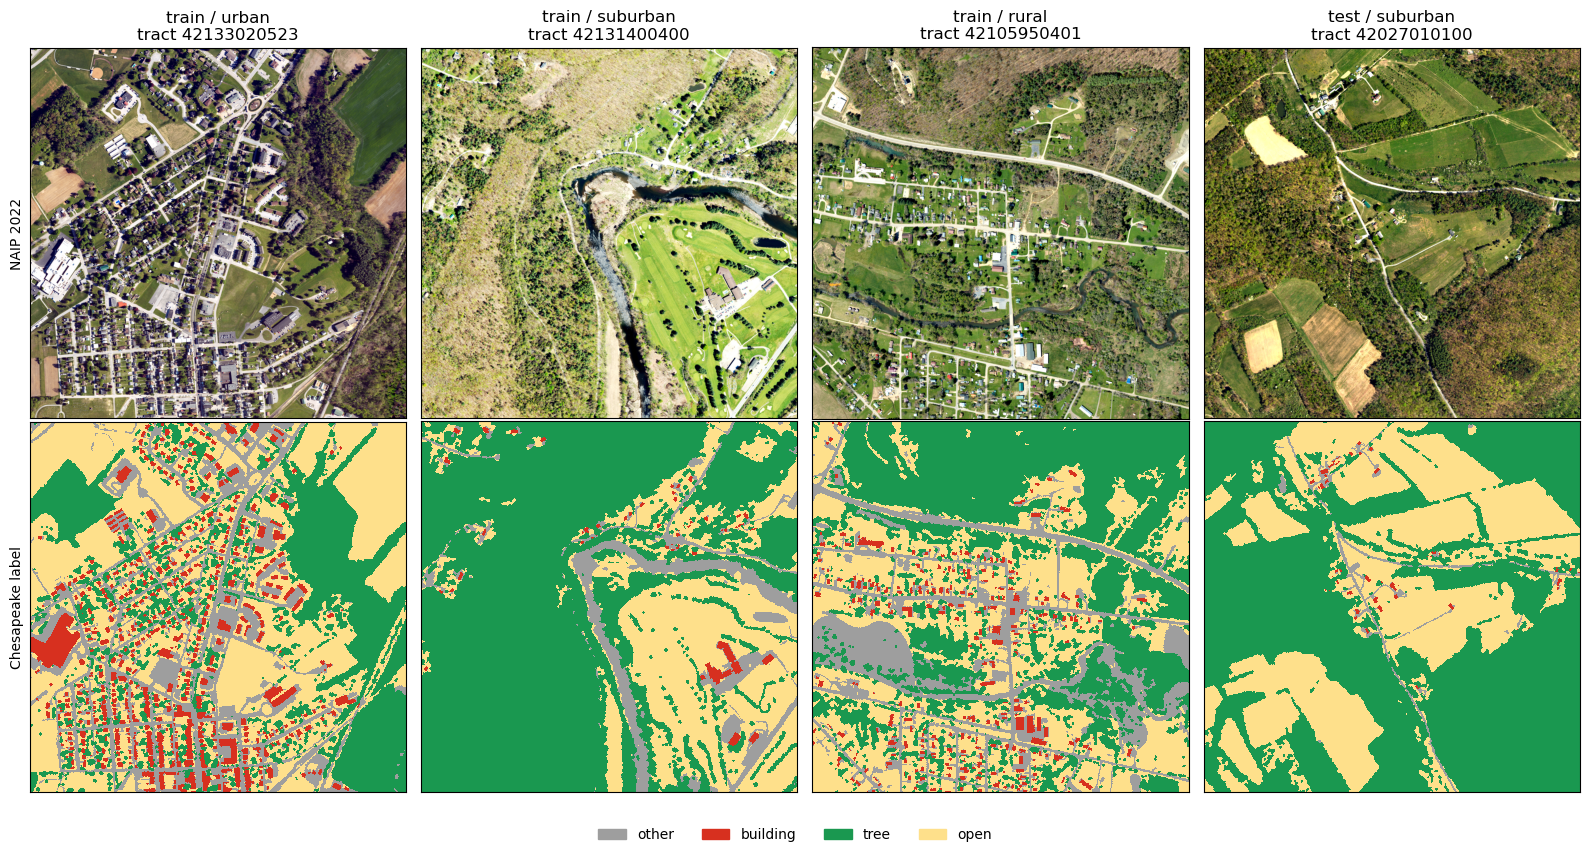

In [2]:
CLASSES = ["other", "building", "tree", "open"]
COLORS = ["#9e9e9e", "#d7301f", "#1a9850", "#fee08b"]
cmap = ListedColormap(COLORS)


def load(geoid):
    with rasterio.open(R6 / "naip" / f"{geoid}.tif") as s:
        img = s.read()
    with rasterio.open(R6 / "labels" / f"{geoid}.tif") as s:
        lab = s.read(1)
    return img, lab


def show_rgb(ax, img):
    rgb = np.moveaxis(img[:3], 0, -1).astype(float)
    lo, hi = np.percentile(rgb, [2, 98])
    ax.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1))


def show_lab(ax, lab):
    ax.imshow(np.ma.masked_equal(lab, 255), cmap=cmap, vmin=0, vmax=3, interpolation="nearest")


# same image grid?
g = boxes.GEOID.iloc[0]
with rasterio.open(R6 / "naip" / f"{g}.tif") as a, rasterio.open(R6 / "labels" / f"{g}.tif") as b:
    print("same grid:", a.transform == b.transform and a.shape == b.shape, a.crs == b.crs)

pick = pd.concat([boxes[(boxes.split == "train") & (boxes.stratum == s)].sample(1, random_state=1) for s in ["urban", "suburban", "rural"]]
                 + [boxes[(boxes.split == "test") & (boxes.stratum == "suburban")].sample(1, random_state=1)])
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for j, (_, b) in enumerate(pick.iterrows()):
    img, lab = load(b.GEOID)
    show_rgb(axes[0, j], img)
    show_lab(axes[1, j], lab)
    axes[0, j].set_title(f"{b.split} / {b.stratum}\ntract {b.GEOID}")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("NAIP 2022")
axes[1, 0].set_ylabel("Chesapeake label")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS]
fig.legend(handles, CLASSES, loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIG / "01_image_vs_label.png", dpi=110)
plt.show()

## Class shares, train vs test

- Big differences = the test is harder

In [3]:
rows = []
for _, b in boxes.iterrows():
    with rasterio.open(R6 / "labels" / f"{b.GEOID}.tif") as s:
        lab = s.read(1)
    cnt = np.bincount(lab.ravel(), minlength=256)
    rows.append({"GEOID": b.GEOID, "split": b.split, "stratum": b.stratum,
                 **{c: cnt[i] for i, c in enumerate(CLASSES)}, "nodata": cnt[255]})
shares = pd.DataFrame(rows)
tab = shares.groupby("split")[CLASSES].sum()
tab = tab.div(tab.sum(axis=1), axis=0).round(3)
print("Share of labeled pixels by split")
print(tab)
tab2 = shares.groupby(["split", "stratum"])[CLASSES].sum()
tab2 = tab2.div(tab2.sum(axis=1), axis=0).round(3)
print("\nBy split and group")
print(tab2)
print("\nNo-data share:", round(shares.nodata.sum() / shares[CLASSES + ["nodata"]].sum().sum(), 4))

Share of labeled pixels by split
       other  building   tree   open
split                               
test   0.147     0.068  0.273  0.512
train  0.143     0.056  0.410  0.391

By split and group
                other  building   tree   open
split stratum                                
test  rural     0.142     0.059  0.249  0.550
      suburban  0.083     0.029  0.314  0.574
      urban     0.216     0.114  0.248  0.422
train rural     0.142     0.049  0.456  0.353
      suburban  0.084     0.029  0.456  0.431
      urban     0.201     0.089  0.322  0.387

No-data share: 0.0007


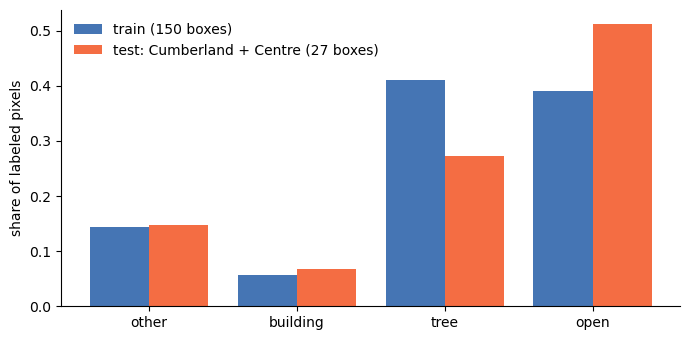

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(CLASSES))
ax.bar(x - 0.2, tab.loc["train"], 0.4, label="train (150 boxes)", color="#4575b4")
ax.bar(x + 0.2, tab.loc["test"], 0.4, label="test: Cumberland + Centre (27 boxes)", color="#f46d43")
ax.set_xticks(x, CLASSES)
ax.set_ylabel("share of labeled pixels")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "01_class_shares.png", dpi=110)
plt.show()

## Pick lots to hand-label

- 200-300 single-family lots
- Mix of Philadelphia, Cumberland, Centre
- Random sample, seed 42
- Look at each one on the NAIP image

**OPTIONAL. TO DO BY YE. Not done yet.**

- Hand labels can only be made by a person looking at the image. Nothing here is filled in by code
- Notebook 05 picks the single-family lots and writes a blank form: `data/processed/hand_labels_template.csv` (250 random lots, seed 42, Philadelphia + Cumberland)
- Centre County has no lot lines in this project, so it is not in the form
- Open each lot at its lon / lat on the NAIP image. Fill `fits` and `fits_keep_trees` with true / false
- Save as `data/processed/hand_labels.csv`. Then re-run notebook 05. Its check section uses the file if it is there

In [5]:
hl = OUT / "hand_labels.csv"
tmpl = OUT / "hand_labels_template.csv"
if hl.exists():
    h = pd.read_csv(hl)
    print(f"hand labels found: {len(h)} lots, {h.fits.notna().sum()} filled in")
else:
    print("No hand_labels.csv yet.", "Blank form is ready:" if tmpl.exists() else "Run notebook 05 to make the blank form.", tmpl.name)

No hand_labels.csv yet. Blank form is ready: hand_labels_template.csv
